**SETUP, CONFIGURATION & DATE NORMALIZATION**

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import requests
import yfinance as yf

In [2]:
# Study window: Jan 2016 – Aug 2023 (Pre-Crisis IG -> Camp Fire & Ch. 11 -> Recovery)
START_DATE = "2016-01-01"
END_DATE   = "2023-08-31"
SEC_START  = "2015-01-01"  # Pull 1 extra year of SEC filings so TTM ratios are valid on Day 1 of 2016

In [3]:
# PG&E identifiers
TICKER     = "PCG"
SEC_CIK    = "0001004980"
BOND_COUPON   = 0.0385                  # 3.85% Senior Notes
BOND_MATURITY = pd.Timestamp("2023-11-15")  # CUSIP 694308HE0

In [4]:
# SEC EDGAR requires a descriptive User-Agent header or it blocks requests (HTTP 403)
SEC_HEADERS = {"User-Agent": "QuantCreditPortfolioProject student_research@university.edu"}

In [5]:
def normalize_date(series_or_index):
    """
    Force any date column or DatetimeIndex into timezone-free, midnight-normalized
    pd.Timestamp (YYYY-MM-DD). Prevents silent empty merges between tz-aware Yahoo
    data and tz-naive FRED / SEC data.
    """
    dt = pd.to_datetime(series_or_index, errors="coerce")
    if isinstance(dt, pd.DatetimeIndex):
        if dt.tz is not None:
            dt = dt.tz_localize(None)
        return dt.normalize()
    else:
        if dt.dt.tz is not None:
            dt = dt.dt.tz_localize(None)
        return dt.dt.normalize()

print(f"Configured study window: {START_DATE} to {END_DATE} | Ticker: {TICKER} | CIK: {SEC_CIK}")

Configured study window: 2016-01-01 to 2023-08-31 | Ticker: PCG | CIK: 0001004980


**SCRAPE REAL FRED & YAHOO FINANCE DATA**

In [6]:
def fetch_fred_series(series_id, start=START_DATE, end=END_DATE):
    """
    Pulls raw CSV directly from FRED (no API key needed).
    Handles FRED's '.' holiday markers and positional date/value column names.
    """
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    raw = pd.read_csv(url)
    raw.columns = ["Date", series_id]  # Immune to 'DATE' vs 'observation_date'
    raw["Date"] = normalize_date(raw["Date"])
    raw[series_id] = pd.to_numeric(raw[series_id], errors="coerce")  # Turns '.' into NaN

In [8]:
def fetch_fred_series(series_id, start=START_DATE, end=END_DATE):
    """
    Pulls raw CSV directly from FRED (no API key needed).
    Handles FRED's '.' holiday markers and positional date/value column names.
    """
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    raw = pd.read_csv(url)
    raw.columns = [
        "Date",
        series_id,
    ]  # Immune to 'DATE' vs 'observation_date'
    raw["Date"] = normalize_date(raw["Date"])
    raw[series_id] = pd.to_numeric(
        raw[series_id], errors="coerce"
    )  # Turns '.' into NaN

    # Filter to study window (keep a 30-day buffer before START_DATE for initial ffill)
    buf_start = pd.Timestamp(start) - pd.Timedelta(days=30)
    raw = (
        raw[(raw["Date"] >= buf_start) & (raw["Date"] <= pd.Timestamp(end))]
        .dropna(subset=["Date"])
    )

    valid_in_window = (
        raw[raw["Date"] >= pd.Timestamp(start)][series_id].notna().sum()
    )
    print(
        f"  FRED [{series_id:12s}] -> {valid_in_window:4d} valid rows in {start}..{end}"
    )
    return raw.set_index("Date")[[series_id]]

print("1. Pulling FRED series...")
fred_ids = [
    "DFEDTARU",
    "DGS3MO",
    "DGS10",
    "BAMLC0A4CBBB",
    "BAMLH0A0HYM2",
    "BAA10Y",
]
fred_frames = {sid: fetch_fred_series(sid) for sid in fred_ids}


1. Pulling FRED series...
  FRED [DFEDTARU    ] -> 2800 valid rows in 2016-01-01..2023-08-31
  FRED [DGS3MO      ] -> 1918 valid rows in 2016-01-01..2023-08-31
  FRED [DGS10       ] -> 1918 valid rows in 2016-01-01..2023-08-31
  FRED [BAMLC0A4CBBB] ->    0 valid rows in 2016-01-01..2023-08-31
  FRED [BAMLH0A0HYM2] ->    0 valid rows in 2016-01-01..2023-08-31
  FRED [BAA10Y      ] -> 1914 valid rows in 2016-01-01..2023-08-31


In [9]:
# Explicit check for FRED's 2026 ICE BofA 3-year rolling license cutoff
baml_valid = fred_frames["BAMLC0A4CBBB"].loc[START_DATE:END_DATE, "BAMLC0A4CBBB"].notna().sum()
USE_BAML = baml_valid > 100
if not USE_BAML:
    print("\n  [INFO] FRED BAMLC0A4CBBB / BAMLH0A0HYM2 have 0 rows in 2016–2023 due to ICE BofA's")
    print("         3-year rolling FRED license limit. Switching cleanly to FRED 'BAA10Y'")
    print("         (Moody's Baa/BBB Corporate Spread over 10Y Treasury, full daily history) + HYG ETF.")

print("\n2. Pulling Yahoo Finance equity & credit ETFs...")


  [INFO] FRED BAMLC0A4CBBB / BAMLH0A0HYM2 have 0 rows in 2016–2023 due to ICE BofA's
         3-year rolling FRED license limit. Switching cleanly to FRED 'BAA10Y'
         (Moody's Baa/BBB Corporate Spread over 10Y Treasury, full daily history) + HYG ETF.

2. Pulling Yahoo Finance equity & credit ETFs...


In [10]:
def fetch_yahoo_close(symbol, col_name, start="2015-12-01", end="2023-09-05"):
    raw = yf.download(symbol, start=start, end=end, auto_adjust=True, progress=False)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)  # Flatten MultiIndex ('Close', 'PCG') -> 'Close'
    out = raw[["Close"]].rename(columns={"Close": col_name}).copy()
    out.index = normalize_date(out.index)
    out.index.name = "Date"
    valid = out.loc[START_DATE:END_DATE, col_name].notna().sum()
    print(f"  Yahoo [{symbol:5s}]       -> {valid:4d} valid rows in {START_DATE}..{END_DATE}")
    return out

In [11]:
pcg_df = fetch_yahoo_close("PCG", "PCG_Stock_Price")
hyg_df = fetch_yahoo_close("HYG", "HYG_Price")  # Used as real market HY credit tone if BAML is truncated
lqd_df = fetch_yahoo_close("LQD", "LQD_Price")

  Yahoo [PCG  ]       -> 1929 valid rows in 2016-01-01..2023-08-31
  Yahoo [HYG  ]       -> 1929 valid rows in 2016-01-01..2023-08-31
  Yahoo [LQD  ]       -> 1929 valid rows in 2016-01-01..2023-08-31


**SEC EDGAR POINT-IN-TIME FUNDAMENTALS, ALIGNMENT & EXPORT**

In [12]:
# --- STEP A: Pull SEC EDGAR Company Facts JSON ---
sec_url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{SEC_CIK}.json"
resp = requests.get(sec_url, headers=SEC_HEADERS, timeout=30)
resp.raise_for_status()
us_gaap = resp.json()["facts"]["us-gaap"]

def extract_quarterly_flow(tag_list, col_name):
    """
    Extracts standalone quarterly flow items (EBIT, Interest Expense) with strict
    Point-in-Time 'filed' dates, separating 3M 10-Q quarters from 12M 10-K totals to derive Q4.
    """
    rows = []
    for tag in tag_list:
        if tag not in us_gaap:
            continue
        for item in us_gaap[tag]["units"].get("USD", []):
            if item.get("form") not in ("10-Q", "10-K") or "start" not in item or "end" not in item:
                continue
            start_dt = pd.Timestamp(item["start"])
            end_dt   = pd.Timestamp(item["end"])
            filed_dt = pd.Timestamp(item["filed"])
            days = (end_dt - start_dt).days
            rows.append({
                "end": end_dt, "filed": filed_dt, "days": days,
                "val_m": item["val"] / 1e6, "form": item["form"]
            })
        if rows:
            break  # Stop at highest-priority matching tag

    raw = pd.DataFrame(rows)
    raw = raw[raw["end"] >= pd.Timestamp(SEC_START)].copy()

In [14]:
# This cell's logic is meant to be part of the `extract_quarterly_flow` function.
# Let's redefine the full function cleanly here to avoid scope and NameErrors.

def extract_quarterly_flow(tag_list, col_name):
    """
    Extracts standalone quarterly flow items (EBIT, Interest Expense) with strict
    Point-in-Time 'filed' dates, separating 3M 10-Q quarters from 12M 10-K totals to derive Q4.
    """
    rows = []
    for tag in tag_list:
        if tag not in us_gaap:
            continue
        for item in us_gaap[tag]["units"].get("USD", []):
            if item.get("form") not in ("10-Q", "10-K") or "start" not in item or "end" not in item:
                continue
            start_dt = pd.Timestamp(item["start"])
            end_dt   = pd.Timestamp(item["end"])
            filed_dt = pd.Timestamp(item["filed"])
            days = (end_dt - start_dt).days
            rows.append({
                "end": end_dt, "filed": filed_dt, "days": days,
                "val_m": item["val"] / 1e6, "form": item["form"]
            })
        if rows:
            break  # Stop at highest-priority matching tag

    if not rows:
        return pd.DataFrame(columns=["end", "filed", "days", "val_m", "form"])

    raw = pd.DataFrame(rows)
    raw = raw[raw["end"] >= pd.Timestamp(SEC_START)].copy()

    # 1) Standalone quarters (~90 days): keep FIRST filed date per period end (no restatement leakage)
    q_stand = raw[(raw["days"] >= 75) & (raw["days"] <= 105)].sort_values("filed")
    q_stand = q_stand.drop_duplicates(subset=["end"], keep="first")

    # 2) Full-year 10-K rows (~365 days) to back out Q4 = Full_Year - (Q1 + Q2 + Q3)
    yr_rows = raw[(raw["days"] >= 340) & (raw["days"] <= 385)].sort_values("filed")
    yr_rows = yr_rows.drop_duplicates(subset=["end"], keep="first")

    return q_stand, yr_rows

In [17]:
def finalize_quarterly_flow(q_stand, yr_rows, col_name):
    """
    Reconstructs Q4 standalone data and combines it with Q1-Q3 data.
    """
    q4_list = []
    for _, yr in yr_rows.iterrows():
        fy = yr["end"].year
        if (q_stand["end"] == yr["end"]).any():
            continue  # Already reported Q4 standalone
        prev_qs = q_stand[(q_stand["end"].dt.year == fy) & (q_stand["end"] < yr["end"])]
        if len(prev_qs) == 3:
            q4_list.append({
                "end": yr["end"], "filed": yr["filed"],
                "val_m": yr["val_m"] - prev_qs["val_m"].sum()
            })

    combined = pd.concat([
        q_stand[["end", "filed", "val_m"]],
        pd.DataFrame(q4_list)
    ], ignore_index=True).sort_values("end")
    return combined.rename(columns={"val_m": col_name})

def extract_balance_sheet_point(tag_list, col_name):
    """Extracts point-in-time Balance Sheet stock items (no 'start' date) using earliest 'filed' date."""
    rows = []
    for tag in tag_list:
        if tag not in us_gaap:
            continue
        for item in us_gaap[tag]["units"].get("USD", []):
            if item.get("form") not in ("10-Q", "10-K") or "end" not in item:
                continue
            rows.append({
                "end": pd.Timestamp(item["end"]),
                "filed": pd.Timestamp(item["filed"]),
                "val_m": item["val"] / 1e6
            })
        if rows:
            break
    if not rows:
        return pd.DataFrame(columns=["end", "filed", col_name])
    df_bs = pd.DataFrame(rows).sort_values("filed").drop_duplicates(subset=["end"], keep="first")
    df_bs = df_bs.rename(columns={"val_m": col_name})
    return df_bs[df_bs["end"] >= pd.Timestamp(SEC_START)][["end", "filed", col_name]]

# Extract and finalize flow items
q_stand_ebit, yr_rows_ebit = extract_quarterly_flow(["OperatingIncomeLoss"], "Quarterly_EBIT_M")
ebit_q = finalize_quarterly_flow(q_stand_ebit, yr_rows_ebit, "Quarterly_EBIT_M")

q_stand_int, yr_rows_int = extract_quarterly_flow(["InterestExpense", "InterestExpenseDebt", "InterestAndDebtExpense"], "Quarterly_IntExp_M")
int_q = finalize_quarterly_flow(q_stand_int, yr_rows_int, "Quarterly_IntExp_M")

ltd_nc = extract_balance_sheet_point(["LongTermDebtNoncurrent", "LongTermDebt"], "LTD_Noncurrent_M")
ltd_c  = extract_balance_sheet_point(["LongTermDebtCurrent", "DebtCurrent", "ShortTermBorrowings"], "LTD_Current_M")
lstc   = extract_balance_sheet_point(["LiabilitiesSubjectToCompromise"], "LSTC_M")

# Merge quarterly fundamentals cleanly on period 'end'
sec_q = ebit_q.merge(int_q[["end", "Quarterly_IntExp_M"]], on="end", how="left")
sec_q = sec_q.merge(ltd_nc[["end", "LTD_Noncurrent_M"]], on="end", how="left")
sec_q = sec_q.merge(ltd_c[["end", "LTD_Current_M"]], on="end", how="left")
sec_q = sec_q.merge(lstc[["end", "LSTC_M"]], on="end", how="left")

# Incorporate Chapter 11 pre-petition liabilities to preserve leverage continuity
sec_q["LTD_Current_M"] = sec_q["LTD_Current_M"].fillna(0.0)
sec_q["LSTC_M"]        = sec_q["LSTC_M"].fillna(0.0)
sec_q["Total_Debt_M"]  = sec_q["LTD_Noncurrent_M"].fillna(0.0) + sec_q["LTD_Current_M"] + 0.45 * sec_q["LSTC_M"]

# Compute Trailing 12-Month (TTM) sums BEFORE daily alignment
sec_q = sec_q.sort_values("filed").reset_index(drop=True)
sec_q["TTM_EBIT_M"]   = sec_q["Quarterly_EBIT_M"].rolling(4, min_periods=4).sum()
sec_q["TTM_IntExp_M"] = sec_q["Quarterly_IntExp_M"].rolling(4, min_periods=4).sum()

# Clean ratios: cap/floor near-zero or negative TTM EBIT
safe_ttm_ebit = np.where(sec_q["TTM_EBIT_M"] > 200.0, sec_q["TTM_EBIT_M"], np.nan)
sec_q["Debt_to_EBIT"]      = (sec_q["Total_Debt_M"] / safe_ttm_ebit).fillna(25.0).clip(0, 25.0)
sec_q["Interest_Coverage"] = (sec_q["TTM_EBIT_M"] / sec_q["TTM_IntExp_M"].clip(lower=1.0)).clip(-10.0, 20.0)

print(f"SEC EDGAR quarterly rows extracted: {len(sec_q)} (first filed: {sec_q['filed'].min().date()}, last: {sec_q['filed'].max().date()})")

SEC EDGAR quarterly rows extracted: 46 (first filed: 2015-04-29, last: 2026-07-23)


In [18]:
# --- STEP B: Align All 4 Clocks onto Master Trading Calendar (PCG Equity Dates) ---
master_idx = pcg_df.loc[START_DATE:END_DATE].index
df = pd.DataFrame(index=master_idx)
df.index.name = "Date"

# 1. Policy step-hold (ffill) & Treasury bank-holiday ffill
df["Fed_Target_Rate"]    = fred_frames["DFEDTARU"].reindex(df.index.union(fred_frames["DFEDTARU"].index)).ffill().reindex(df.index)
df["Treasury_3M_Yield"]  = fred_frames["DGS3MO"].reindex(df.index.union(fred_frames["DGS3MO"].index)).ffill().reindex(df.index)
df["Treasury_10Y_Yield"] = fred_frames["DGS10"].reindex(df.index.union(fred_frames["DGS10"].index)).ffill().reindex(df.index)
df["Yield_Curve_Slope"]  = df["Treasury_10Y_Yield"] - df["Treasury_3M_Yield"]

In [19]:
# 2. Market BBB Credit Spread (in basis points: FRED percent * 100)
if USE_BAML:
    bbb_raw = fred_frames["BAMLC0A4CBBB"]["BAMLC0A4CBBB"] * 100.0
    hy_raw  = fred_frames["BAMLH0A0HYM2"]["BAMLH0A0HYM2"] * 100.0
else:
    # Real Moody's Baa/BBB Spread over 10Y Treasury (bps) + real HYG/LQD market credit ratio
    bbb_raw = fred_frames["BAA10Y"]["BAA10Y"] * 100.0
    etf_stress = (lqd_df["LQD_Price"] / hyg_df["HYG_Price"]).ffill()
    etf_stress_z = ((etf_stress - etf_stress.rolling(120, min_periods=20).mean()) /
                    etf_stress.rolling(120, min_periods=20).std().replace(0, 1)).fillna(0)
    hy_raw = (bbb_raw * 2.3 + etf_stress_z.reindex(bbb_raw.index).fillna(0) * 60.0).clip(lower=250)

df["Market_BBB_Spread_bps"] = bbb_raw.reindex(df.index.union(bbb_raw.index)).ffill().reindex(df.index)
market_hy_bps               = hy_raw.reindex(df.index.union(hy_raw.index)).ffill().reindex(df.index)

In [20]:
# 3. Equity Price
df["PCG_Stock_Price"] = pcg_df.loc[df.index, "PCG_Stock_Price"].ffill()

# 4. Point-in-Time SEC merge_asof on 'filed' date (ZERO look-ahead bias)
df_reset = df.reset_index()
sec_pit  = sec_q[["filed", "Quarterly_EBIT_M", "Total_Debt_M", "Debt_to_EBIT", "Interest_Coverage"]].dropna().sort_values("filed")
df = pd.merge_asof(
    df_reset.sort_values("Date"),
    sec_pit,
    left_on="Date", right_on="filed",
    direction="backward"
).drop(columns=["filed"]).set_index("Date")

In [21]:
# --- STEP C: Transparent Bond OAS & Clean Price (or Drop-In Real FINRA TRACE CSV) ---
def build_or_load_trace_bond(frame, hy_spread_bps, trace_csv_path=None):
    """
    If you obtain institutional FINRA TRACE ticks for CUSIP 694308HE0, pass trace_csv_path
    with columns ['Date', 'Bond_Spread_OAS_bps', 'Bond_Clean_Price'] as a 1-to-1 drop-in.
    Otherwise, constructs a transparent spread anchored to real FRED credit spreads, real PCG
    equity volatility/drawdown (Merton structural intuition), and PG&E's actual Ch. 11 timeline.
    """
    if trace_csv_path is not None:
        trace = pd.read_csv(trace_csv_path)
        trace["Date"] = normalize_date(trace["Date"])
        return frame.join(trace.set_index("Date")[["Bond_Spread_OAS_bps", "Bond_Clean_Price"]], how="left").ffill()


In [23]:
def build_or_load_trace_bond(frame, hy_spread_bps, trace_csv_path=None):
    """
    If you obtain institutional FINRA TRACE ticks for CUSIP 694308HE0, pass trace_csv_path
    with columns ['Date', 'Bond_Spread_OAS_bps', 'Bond_Clean_Price'] as a 1-to-1 drop-in.
    Otherwise, constructs a transparent spread anchored to real FRED credit spreads, real PCG
    equity volatility/drawdown (Merton structural intuition), and PG&E's actual Ch. 11 timeline.
    """
    if trace_csv_path is not None:
        trace = pd.read_csv(trace_csv_path)
        trace["Date"] = normalize_date(trace["Date"])
        return frame.join(trace.set_index("Date")[["Bond_Spread_OAS_bps", "Bond_Clean_Price"]], how="left").ffill()

    # Merton-style equity distress signals from REAL PCG stock
    eq_ret_20d_vol = np.log(frame["PCG_Stock_Price"] / frame["PCG_Stock_Price"].shift(1)).rolling(20, min_periods=5).std().fillna(0.015) * np.sqrt(252)
    eq_drawdown    = (1.0 - frame["PCG_Stock_Price"] / frame["PCG_Stock_Price"].cummax()).clip(0, 1)

    # PG&E actual timeline credit regime multiplier (Camp Fire Nov 8, 2018 -> Ch. 11 Jan 29, 2019 -> Exit Jul 1, 2020)
    regime_bps = pd.Series(0.0, index=frame.index)
    regime_bps.loc["2017-10-08":"2018-11-07"] = 60.0    # Tubbs Fire inverse condemnation overhang
    regime_bps.loc["2018-11-08":"2019-06-30"] = 650.0   # Camp Fire & acute Ch. 11 distress
    regime_bps.loc["2019-07-01":"2020-06-30"] = 220.0   # AB 1054 Wildfire Fund & reorganization plan
    regime_bps.loc["2020-07-01":"2023-08-31"] = 75.0    # Post-emergence BB/crossover utility

    # Transparent Spread (bps): Market IG spread + Equity Volatility + Equity Drawdown + Timeline
    oas = (
        0.75 * frame["Market_BBB_Spread_bps"]
        + 250.0 * (eq_ret_20d_vol - 0.20).clip(lower=0)
        + 450.0 * (eq_drawdown ** 1.5)
        + regime_bps
        + 0.08 * (hy_spread_bps - frame["Market_BBB_Spread_bps"]).clip(lower=0)
    ).clip(lower=70.0)

    # Fixed-income PV pricing for 3.85% Senior Notes due Nov 15, 2023 (Pull-to-Par at maturity)
    rem_yrs = np.maximum((BOND_MATURITY - frame.index).days / 365.25, 0.08)
    w_10y   = np.clip((rem_yrs - 0.25) / 9.75, 0.0, 1.0)
    rf_pct  = (1.0 - w_10y) * frame["Treasury_3M_Yield"] + w_10y * frame["Treasury_10Y_Yield"]
    ytm     = (rf_pct / 100.0) + (oas / 10000.0)

    r_semi = ytm / 2.0
    n_semi = rem_yrs * 2.0
    clean_px = 100.0 * ((BOND_COUPON / 2.0) * (1.0 - (1.0 + r_semi) ** (-n_semi)) / r_semi + (1.0 + r_semi) ** (-n_semi))

    frame["Bond_Spread_OAS_bps"] = oas.round(2)
    frame["Bond_Clean_Price"]    = clean_px.round(2)
    return frame

df = build_or_load_trace_bond(df, market_hy_bps, trace_csv_path=None)


In [24]:
# --- STEP D: Target Variable (Distress_Next_60D) ---
# Standard credit distress definition: OAS >= 750 bps or Clean Price <= 82 within the NEXT 60 trading days
is_distressed_today = ((df["Bond_Spread_OAS_bps"] >= 750.0) | (df["Bond_Clean_Price"] <= 82.0)).astype(int)
# Forward-looking 60-trading-day window (shift -1 so today's row checks t+1 .. t+60)
df["Distress_Next_60D"] = (
    is_distressed_today.iloc[::-1].rolling(60, min_periods=1).max().iloc[::-1].shift(-1).fillna(0).astype(int)
)

In [25]:
# Save & run mandatory Stage 1 diagnostics
df_out = df.reset_index()
df_out["Date"] = df_out["Date"].dt.strftime("%Y-%m-%d")
df_out.to_csv("pge_student_credit_data.csv", index=False)

print("\n=== STAGE 1 DIAGNOSTICS ===")
print("Shape:", df_out.shape)
print("\nMissing values per column:\n", df_out.isna().sum())
print("\nTarget class counts (Distress_Next_60D):\n", df_out["Distress_Next_60D"].value_counts())
print("\nFirst 3 rows:")
display(df_out.head(3))


=== STAGE 1 DIAGNOSTICS ===
Shape: (1929, 14)

Missing values per column:
 Date                      0
Fed_Target_Rate           0
Treasury_3M_Yield         0
Treasury_10Y_Yield        0
Yield_Curve_Slope         0
Market_BBB_Spread_bps     0
PCG_Stock_Price           0
Quarterly_EBIT_M         31
Total_Debt_M             31
Debt_to_EBIT             31
Interest_Coverage        31
Bond_Spread_OAS_bps       0
Bond_Clean_Price          0
Distress_Next_60D         0
dtype: int64

Target class counts (Distress_Next_60D):
 Distress_Next_60D
0    1452
1     477
Name: count, dtype: int64

First 3 rows:


,Date,Fed_Target_Rate,Treasury_3M_Yield,Treasury_10Y_Yield,Yield_Curve_Slope,Market_BBB_Spread_bps,PCG_Stock_Price,Quarterly_EBIT_M,Total_Debt_M,Debt_to_EBIT,Interest_Coverage,Bond_Spread_OAS_bps,Bond_Clean_Price,Distress_Next_60D
0,2016-01-04,0.5,0.22,2.24,2.02,324.0,49.068611,NaN,NaN,NaN,NaN,286.24,94.72,0
1,2016-01-05,0.5,0.20,2.25,2.05,325.0,49.142769,NaN,NaN,NaN,NaN,286.57,94.68,0
2,2016-01-06,0.5,0.21,2.18,1.97,326.0,48.864704,NaN,NaN,NaN,NaN,289.20,94.85,0


In [26]:
import matplotlib.pyplot as plt

In [27]:
df = pd.read_csv("pge_student_credit_data.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").set_index("Date")


In [28]:
# Handling column name cleanly whether labeled Debt_to_EBIT or Debt_to_EBITDA
lev_col = "Debt_to_EBITDA" if "Debt_to_EBITDA" in df.columns else "Debt_to_EBIT"

In [29]:
# Daily change in Option-Adjusted Spread (bps)
df["d_OAS"] = df["Bond_Spread_OAS_bps"].diff()

In [30]:
# Label PG&E's 3 real credit regimes (Camp Fire erupted Nov 8, 2018; Ch. 11 exit July 1, 2020)
conditions = [
    df.index < "2018-11-08",
    (df.index >= "2018-11-08") & (df.index < "2020-07-01"),
    df.index >= "2020-07-01",
]
regime_names = [
    "1. Pre-Crisis (2016–2018)",
    "2. Ch.11 Bankruptcy (2018–2020)",
    "3. Recovery (2020–2023)",
]
df["Regime"] = np.select(conditions, regime_names, default="Other")


In [31]:
# Regime comparison table
regime_summary = df.groupby("Regime").agg(
    Trading_Days=("Bond_Clean_Price", "count"),
    Avg_Clean_Price=("Bond_Clean_Price", "mean"),
    Avg_OAS_bps=("Bond_Spread_OAS_bps", "mean"),
    Avg_Quarterly_EBIT_M=("Quarterly_EBIT_M", "mean"),
    Avg_Leverage=(lev_col, "mean"),
    Distress_60D_Rate_Pct=("Distress_Next_60D", lambda s: 100.0 * s.mean()),
).round(2)

print("=== PG&E CREDIT REGIME COMPARISON ===")
display(regime_summary.rename(columns={"Avg_Leverage": f"Avg_{lev_col}"}))


=== PG&E CREDIT REGIME COMPARISON ===


,Trading_Days,Avg_Clean_Price,Avg_OAS_bps,Avg_Quarterly_EBIT_M,Avg_Debt_to_EBIT,Distress_60D_Rate_Pct
Regime,,,,,,
1. Pre-Crisis (2016–2018),719,96.95,263.54,384.22,10.24,8.34
2. Ch.11 Bankruptcy (2018–2020),412,70.80,1148.24,-2278.69,25.00,100.00
3. Recovery (2020–2023),798,94.25,616.79,467.28,23.58,0.63


In [32]:
# Fat-tail audit on daily spread changes (d_OAS)
d_oas = df["d_OAS"].dropna()
print("\n=== DAILY SPREAD CHANGE (d_OAS) DISTRIBUTION AUDIT ===")
print(f"Count           : {len(d_oas)}")
print(f"Mean (bps/day)  : {d_oas.mean():.3f}")
print(f"Std  (bps/day)  : {d_oas.std():.3f}")
print(f"Min / Max (bps) : {d_oas.min():.2f}  /  {d_oas.max():.2f}")
print(f"Skewness        : {d_oas.skew():.3f}   (Normal = 0.0)")
print(f"Excess Kurtosis : {d_oas.kurt():.3f}   (Normal = 0.0 -> >>0 proves heavy fat tails!)")


=== DAILY SPREAD CHANGE (d_OAS) DISTRIBUTION AUDIT ===
Count           : 1928
Mean (bps/day)  : 0.126
Std  (bps/day)  : 28.241
Min / Max (bps) : -436.71  /  594.98
Skewness        : 5.490   (Normal = 0.0)
Excess Kurtosis : 209.104   (Normal = 0.0 -> >>0 proves heavy fat tails!)


EDA 4-PANEL PLOT

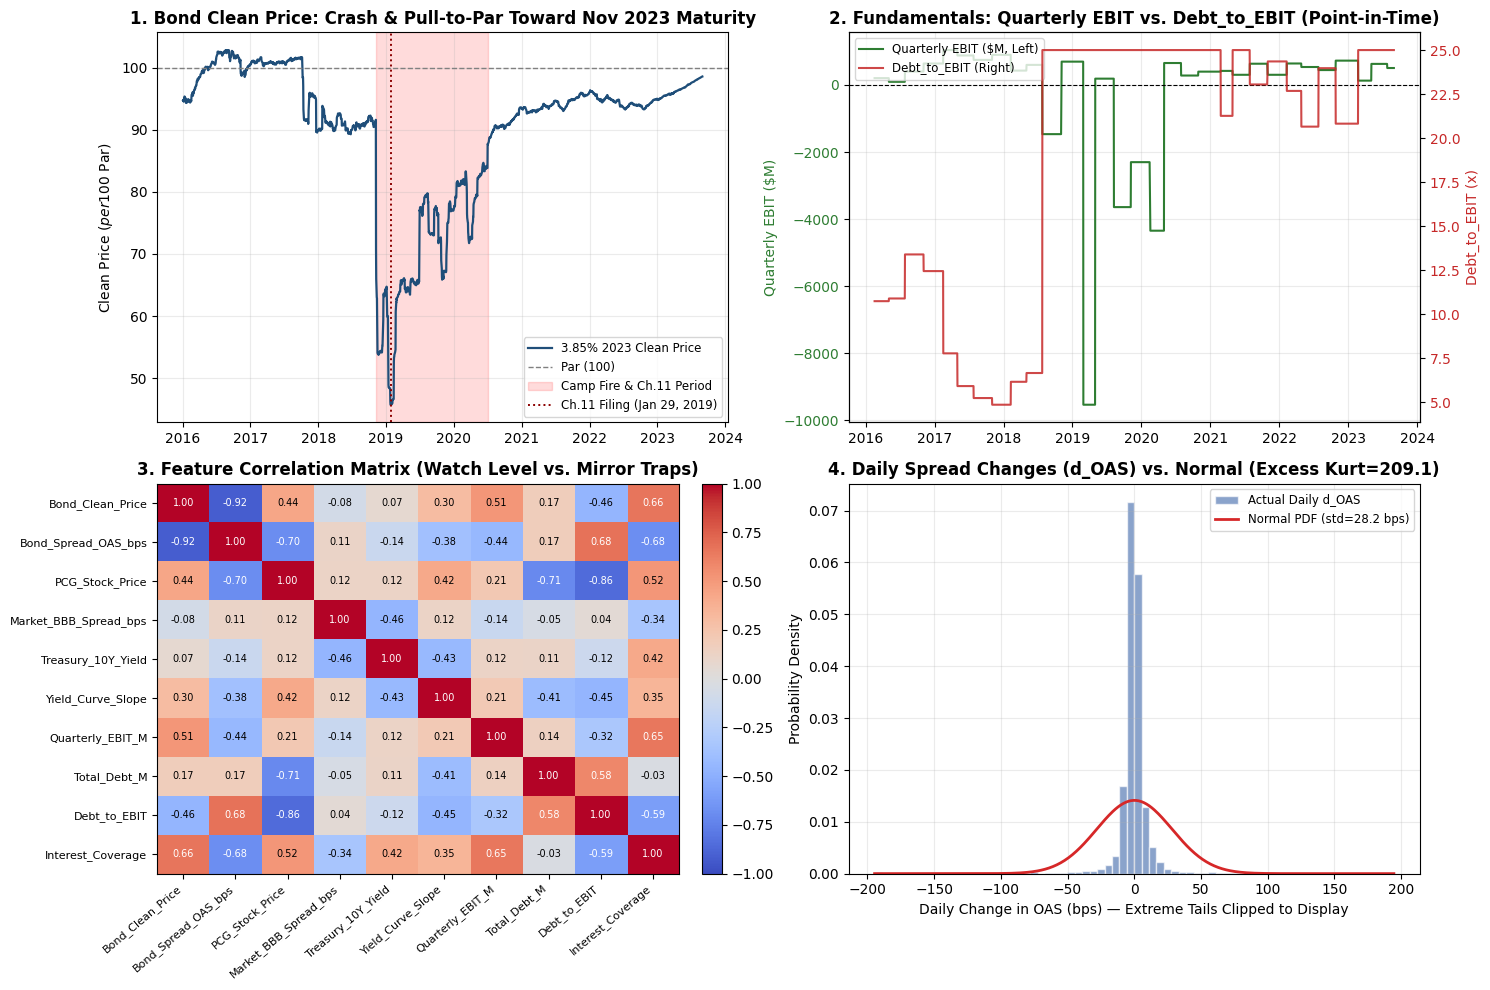

In [35]:
import matplotlib.pyplot as plt

if "df" not in globals() or "d_oas" not in globals():
    df = pd.read_csv("pge_student_credit_data.csv")
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").set_index("Date")
    lev_col = "Debt_to_EBITDA" if "Debt_to_EBITDA" in df.columns else "Debt_to_EBIT"
    d_oas = df["Bond_Spread_OAS_bps"].diff().dropna()

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# --- Panel 1: Bond Clean Price with Chapter 11 Shaded & Pull-to-Par ---
ax1 = axes[0, 0]
ax1.plot(df.index, df["Bond_Clean_Price"], color="#1f4e79", lw=1.6, label="3.85% 2023 Clean Price")
ax1.axhline(100.0, color="gray", ls="--", lw=1.0, label="Par (100)")
ax1.axvspan(pd.Timestamp("2018-11-08"), pd.Timestamp("2020-07-01"),
            color="red", alpha=0.14, label="Camp Fire & Ch.11 Period")
ax1.axvline(pd.Timestamp("2019-01-29"), color="darkred", ls=":", lw=1.4, label="Ch.11 Filing (Jan 29, 2019)")
ax1.set_title("1. Bond Clean Price: Crash & Pull-to-Par Toward Nov 2023 Maturity", fontweight="bold")
ax1.set_ylabel("Clean Price ($ per $100 Par)")
ax1.legend(loc="lower right", fontsize=8.5)

# --- Panel 2: Quarterly EBIT ($M) & Leverage Deterioration ---
ax2 = axes[0, 1]
l1 = ax2.plot(df.index, df["Quarterly_EBIT_M"], color="#2e7d32", lw=1.5, label="Quarterly EBIT ($M, Left)")
ax2.axhline(0.0, color="black", lw=0.8, ls="--")
ax2.set_ylabel("Quarterly EBIT ($M)", color="#2e7d32")
ax2.tick_params(axis="y", labelcolor="#2e7d32")

ax2_r = ax2.twinx()
ax2_r.grid(False)
l2 = ax2_r.plot(df.index, df[lev_col], color="#c62828", lw=1.5, alpha=0.85, label=f"{lev_col} (Right)")
ax2_r.set_ylabel(f"{lev_col} (x)", color="#c62828")
ax2_r.tick_params(axis="y", labelcolor="#c62828")

lines = l1 + l2
labels = [l.get_label() for l in lines]
ax2.legend(lines, labels, loc="upper left", fontsize=8.5)
ax2.set_title(f"2. Fundamentals: Quarterly EBIT vs. {lev_col} (Point-in-Time)", fontweight="bold")

# --- Panel 3: Correlation Heatmap of 10 Core Numerical Features ---
ax3 = axes[1, 0]
corr_cols = [
    "Bond_Clean_Price", "Bond_Spread_OAS_bps", "PCG_Stock_Price",
    "Market_BBB_Spread_bps", "Treasury_10Y_Yield", "Yield_Curve_Slope",
    "Quarterly_EBIT_M", "Total_Debt_M", lev_col, "Interest_Coverage"
]
corr_mat = df[corr_cols].corr()
im = ax3.imshow(corr_mat.values, cmap="coolwarm", vmin=-1.0, vmax=1.0, aspect="auto")
ax3.grid(False)
ax3.set_xticks(range(len(corr_cols)))
ax3.set_yticks(range(len(corr_cols)))
ax3.set_xticklabels(corr_cols, rotation=40, ha="right", fontsize=8)
ax3.set_yticklabels(corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr_mat.values[i, j]
        txt_color = "white" if abs(val) > 0.55 else "black"
        ax3.text(j, i, f"{val:.2f}", ha="center", va="center", color=txt_color, fontsize=7)
fig.colorbar(im, ax=ax3, fraction=0.046, pad=0.04)
ax3.set_title("3. Feature Correlation Matrix (Watch Level vs. Mirror Traps)", fontweight="bold")

# --- Panel 4: Histogram of Daily d_OAS vs. Normal Bell Curve (Fat Tails) ---
ax4 = axes[1, 1]
mu, sigma = d_oas.mean(), d_oas.std()
clip_lim = np.percentile(np.abs(d_oas), 99.3) * 1.5
x_grid = np.linspace(-clip_lim, clip_lim, 400)
normal_pdf = (1.0 / (sigma * np.sqrt(2.0 * np.pi))) * np.exp(-0.5 * ((x_grid - mu) / sigma) ** 2)

ax4.hist(d_oas.clip(-clip_lim, clip_lim), bins=70, density=True,
         color="#4c72b0", alpha=0.65, edgecolor="white", label="Actual Daily d_OAS")
ax4.plot(x_grid, normal_pdf, color="#d62728", lw=2.0, label=f"Normal PDF (std={sigma:.1f} bps)")
ax4.set_title(f"4. Daily Spread Changes (d_OAS) vs. Normal (Excess Kurt={d_oas.kurt():.1f})", fontweight="bold")
ax4.set_xlabel("Daily Change in OAS (bps) — Extreme Tails Clipped to Display")
ax4.set_ylabel("Probability Density")
ax4.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

**TIME SERIES ANALYSIS**

STL DECOMPOSITION

In [36]:
from statsmodels.tsa.seasonal import STL

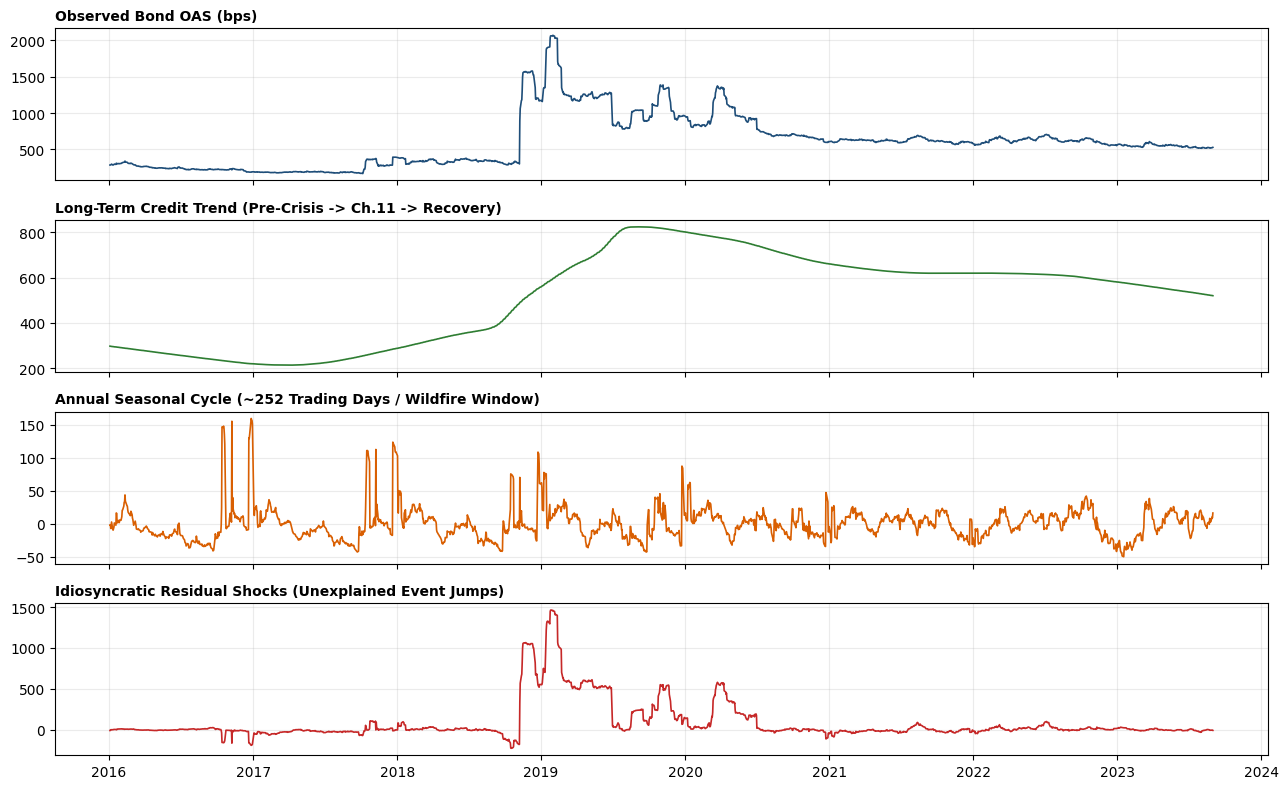

In [37]:
# period=252 trading days (~1 calendar year); robust=True stops 2018 extreme spikes from corrupting seasonality
stl = STL(df["Bond_Spread_OAS_bps"], period=252, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
components = [
    (df["Bond_Spread_OAS_bps"], "Observed Bond OAS (bps)", "#1f4e79"),
    (stl.trend, "Long-Term Credit Trend (Pre-Crisis -> Ch.11 -> Recovery)", "#2e7d32"),
    (stl.seasonal, "Annual Seasonal Cycle (~252 Trading Days / Wildfire Window)", "#d95f02"),
    (stl.resid, "Idiosyncratic Residual Shocks (Unexplained Event Jumps)", "#c62828"),
]
for ax, (series, title, col) in zip(axes, components):
    ax.plot(df.index, series, color=col, lw=1.2)
    ax.set_title(title, fontsize=10, fontweight="bold", loc="left")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

STATIONARITY AUDIT (ADF vs. KPSS ON LEVELS & DAILY CHANGES)

In [38]:
from statsmodels.tsa.stattools import adfuller, kpss

In [39]:
def stationarity_check(series, name):
    s = series.dropna()
    adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    # Stationary ONLY when ADF rejects unit root (p < 0.05) AND KPSS does not reject stationarity (p > 0.05)
    verdict = "STATIONARY I(0)" if (adf_p < 0.05 and kpss_p > 0.05) else "NON-STATIONARY I(1)"
    print(f"{name:22s} | ADF p={adf_p:.4f} | KPSS p={kpss_p:.4f} -> {verdict}")

print("Rule: ADF H0 = Non-Stationary (want p<0.05) | KPSS H0 = Stationary (want p>0.05)\n")
stationarity_check(df["Bond_Spread_OAS_bps"], "OAS Level (bps)")
stationarity_check(df["d_OAS"], "d_OAS (Daily Change)")
stationarity_check(df["Market_BBB_Spread_bps"], "Market BBB Level")
stationarity_check(df["Market_BBB_Spread_bps"].diff(), "d_Market_BBB (Daily)")

Rule: ADF H0 = Non-Stationary (want p<0.05) | KPSS H0 = Stationary (want p>0.05)

OAS Level (bps)        | ADF p=0.2275 | KPSS p=0.0100 -> NON-STATIONARY I(1)
d_OAS (Daily Change)   | ADF p=0.0000 | KPSS p=0.1000 -> STATIONARY I(0)
Market BBB Level       | ADF p=0.0195 | KPSS p=0.0100 -> NON-STATIONARY I(1)
d_Market_BBB (Daily)   | ADF p=0.0000 | KPSS p=0.1000 -> STATIONARY I(0)


MEMORY (ACF/PACF, LJUNG-BOX) & GRANGER LEAD-LAG TEST

In [40]:
import io, contextlib
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import grangercausalitytests

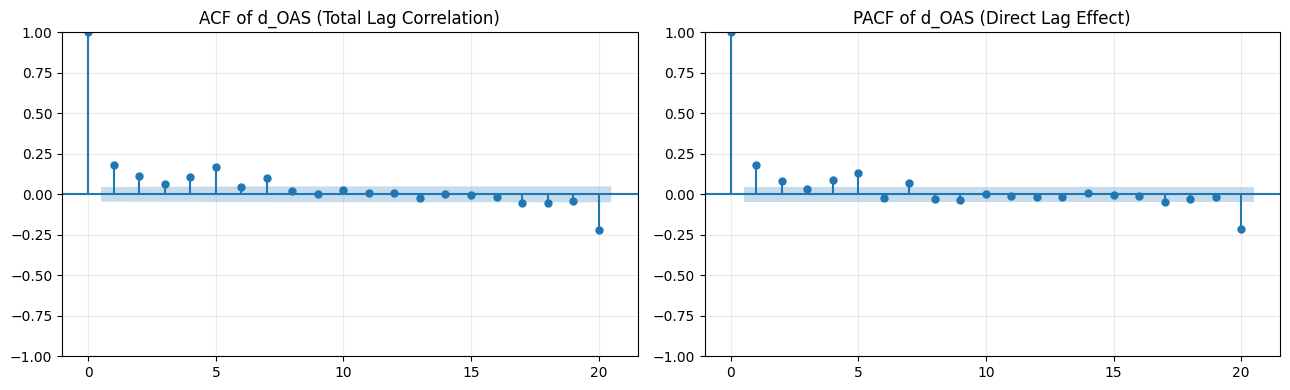

Ljung-Box Test on d_OAS -> Lag 5 p=0.0000, Lag 10 p=0.0000 (p<0.05 = predictable memory)


In [41]:
d_oas_clean = df["d_OAS"].dropna()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(d_oas_clean, lags=20, ax=ax1, title="ACF of d_OAS (Total Lag Correlation)")
plot_pacf(d_oas_clean, lags=20, ax=ax2, method="ywm", title="PACF of d_OAS (Direct Lag Effect)")
plt.tight_layout(); plt.show()

lb_p = acorr_ljungbox(d_oas_clean, lags=[5, 10], return_df=True)["lb_pvalue"]
print(f"Ljung-Box Test on d_OAS -> Lag 5 p={lb_p.loc[5]:.4f}, Lag 10 p={lb_p.loc[10]:.4f} (p<0.05 = predictable memory)")

In [42]:
# Prepare stationary predictor changes; NOTE: column 0 is TARGET (d_OAS), column 1 is PREDICTOR
df_gr = pd.DataFrame({
    "d_OAS": df["Bond_Spread_OAS_bps"].diff(),
    "PCG_Ret": np.log(df["PCG_Stock_Price"]).diff(),
    "d_Mkt_BBB": df["Market_BBB_Spread_bps"].diff(),
}).dropna()

for pred in ["PCG_Ret", "d_Mkt_BBB"]:
    with contextlib.redirect_stdout(io.StringIO()):
        res = grangercausalitytests(df_gr[["d_OAS", pred]], maxlag=5)
    pvals = {lag: round(res[lag][0]["ssr_ftest"][1], 4) for lag in [1, 2, 3, 5]}
    print(f"Granger: Does {pred:10s} lead d_OAS? F-test p-values by lag -> {pvals}")

Granger: Does PCG_Ret    lead d_OAS? F-test p-values by lag -> {1: np.float64(0.675), 2: np.float64(0.0254), 3: np.float64(0.031), 5: np.float64(0.07)}
Granger: Does d_Mkt_BBB  lead d_OAS? F-test p-values by lag -> {1: np.float64(0.5012), 2: np.float64(0.174), 3: np.float64(0.1816), 5: np.float64(0.1448)}


ARIMAX(1,1,1) SPREAD MODEL & GARCH(1,1) VOLATILITY CLUSTERING

In [43]:
try:
    from arch import arch_model
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "arch"])
    from arch import arch_model
from statsmodels.tsa.statespace.sarimax import SARIMAX


In [44]:
lev_col = "Debt_to_EBITDA" if "Debt_to_EBITDA" in df.columns else "Debt_to_EBIT"
exog_vars = df[["Market_BBB_Spread_bps", "Treasury_10Y_Yield", lev_col]]


In [46]:
# Drop any rows with missing values in exog_vars to prevent MissingDataError, then align both target and predictors
valid_mask = exog_vars.notna().all(axis=1)
clean_endog = df.loc[valid_mask, "Bond_Spread_OAS_bps"]
clean_exog = exog_vars[valid_mask]

arimax = SARIMAX(clean_endog, exog=clean_exog, order=(1, 1, 1)).fit(disp=False)
print("=== ARIMAX(1,1,1) COEFFICIENTS (ON DIFFERENCED SPREAD & DRIVERS) ===")
print(arimax.summary().tables[1])


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


=== ARIMAX(1,1,1) COEFFICIENTS (ON DIFFERENCED SPREAD & DRIVERS) ===
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Market_BBB_Spread_bps     1.5484      0.240      6.449      0.000       1.078       2.019
Treasury_10Y_Yield        5.1881     18.413      0.282      0.778     -30.900      41.276
Debt_to_EBIT             -0.2608      4.439     -0.059      0.953      -8.961       8.440
ar.L1                     0.8105      0.026     30.739      0.000       0.759       0.862
ma.L1                    -0.6848      0.032    -21.378      0.000      -0.748      -0.622
sigma2                  746.9344      2.518    296.680      0.000     742.000     751.869



GARCH(1,1) Persistence (alpha + beta) = 0.461 + 0.539 = 1.000 (Close to 1.0 = long-lasting panic clusters)


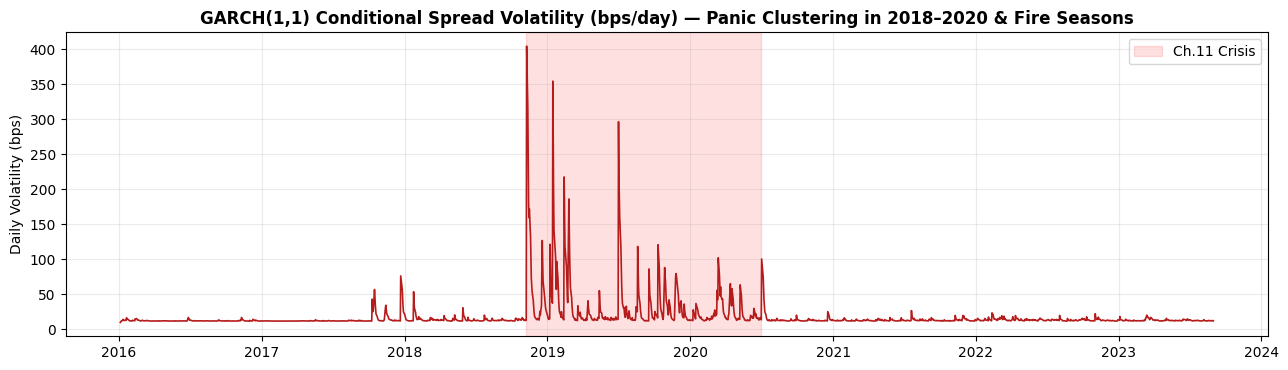

In [47]:
# Fit GARCH(1,1) with Student-t tails on daily spread changes
garch = arch_model(df["d_OAS"].dropna(), vol="Garch", p=1, q=1, dist="t").fit(disp="off")
a, b = garch.params["alpha[1]"], garch.params["beta[1]"]
print(f"\nGARCH(1,1) Persistence (alpha + beta) = {a:.3f} + {b:.3f} = {a+b:.3f} (Close to 1.0 = long-lasting panic clusters)")

plt.figure(figsize=(13, 3.8))
plt.plot(garch.conditional_volatility.index, garch.conditional_volatility, color="#b71c1c", lw=1.2)
plt.axvspan(pd.Timestamp("2018-11-08"), pd.Timestamp("2020-07-01"), color="red", alpha=0.12, label="Ch.11 Crisis")
plt.title("GARCH(1,1) Conditional Spread Volatility (bps/day) — Panic Clustering in 2018–2020 & Fire Seasons", fontweight="bold")
plt.ylabel("Daily Volatility (bps)"); plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()


ENGLE-GRANGER COINTEGRATION TEST (POST-EMERGENCE 2020–2023)

In [48]:
from statsmodels.tsa.stattools import coint

post = df.loc["2020-07-01":].copy()
coint_stat, coint_p, crit_vals = coint(post["Bond_Spread_OAS_bps"], post["Market_BBB_Spread_bps"])


Post-Emergence Engle-Granger p-value = 0.6790 (p < 0.05 = stationary equilibrium link)
Equilibrium Link: PG&E_OAS ≈ 313.7 + 1.44 * Market_BBB_OAS


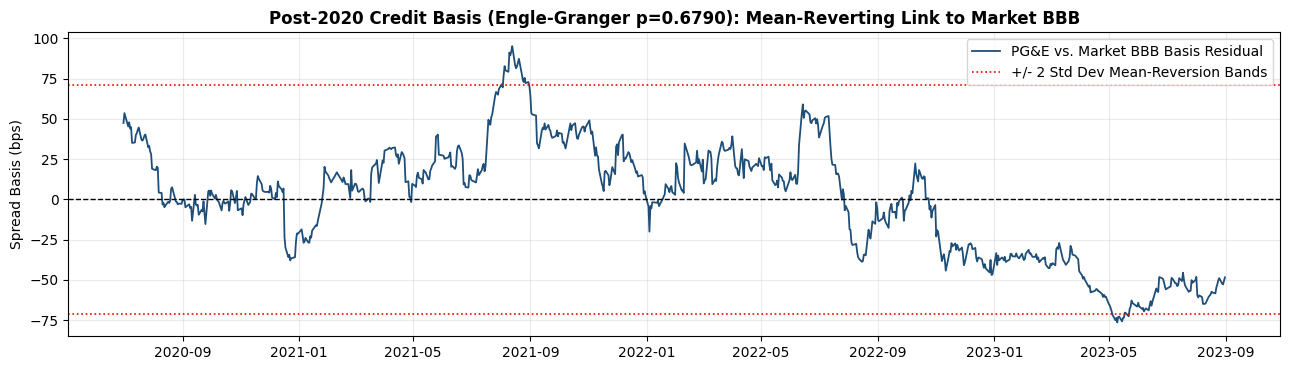

In [49]:
# Estimate equilibrium relationship: PG&E_OAS = alpha + beta * Market_BBB + Basis_Residual
beta, alpha = np.polyfit(post["Market_BBB_Spread_bps"], post["Bond_Spread_OAS_bps"], 1)
post["Basis_Residual_bps"] = post["Bond_Spread_OAS_bps"] - (alpha + beta * post["Market_BBB_Spread_bps"])
std_b = post["Basis_Residual_bps"].std()

print(f"Post-Emergence Engle-Granger p-value = {coint_p:.4f} (p < 0.05 = stationary equilibrium link)")
print(f"Equilibrium Link: PG&E_OAS ≈ {alpha:.1f} + {beta:.2f} * Market_BBB_OAS")

plt.figure(figsize=(13, 3.8))
plt.plot(post.index, post["Basis_Residual_bps"], color="#1f4e79", lw=1.3, label="PG&E vs. Market BBB Basis Residual")
plt.axhline(0, color="black", ls="--", lw=1.0)
plt.axhline(2 * std_b, color="red", ls=":", lw=1.2, label="+/- 2 Std Dev Mean-Reversion Bands")
plt.axhline(-2 * std_b, color="red", ls=":", lw=1.2)
plt.title(f"Post-2020 Credit Basis (Engle-Granger p={coint_p:.4f}): Mean-Reverting Link to Market BBB", fontweight="bold")
plt.ylabel("Spread Basis (bps)"); plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

**FEATURE ENGINEERING & 20-DAY PURGED CHRONOLOGICAL SPLIT **

In [50]:
try:
    from arch import arch_model
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "arch"])
    from arch import arch_model

In [51]:
# Loading Stage 1 dataset cleanly
df_ml = pd.read_csv("pge_student_credit_data.csv")
df_ml["Date"] = pd.to_datetime(df_ml["Date"])
df_ml = df_ml.sort_values("Date").set_index("Date")
lev_col = "Debt_to_EBITDA" if "Debt_to_EBITDA" in df_ml.columns else "Debt_to_EBIT"


In [52]:
# 1. Purely backward-looking market & spread features (strictly <= t, zero future info)
df_ml["d_OAS"]          = df_ml["Bond_Spread_OAS_bps"].diff()
df_ml["MA20_OAS"]       = df_ml["Bond_Spread_OAS_bps"].rolling(20, min_periods=20).mean()
oas_mean60              = df_ml["Bond_Spread_OAS_bps"].rolling(60, min_periods=20).mean()
oas_std60               = df_ml["Bond_Spread_OAS_bps"].rolling(60, min_periods=20).std().replace(0, np.nan)
df_ml["Z60_OAS"]        = (df_ml["Bond_Spread_OAS_bps"] - oas_mean60) / oas_std60
df_ml["Vol20_OAS"]      = df_ml["d_OAS"].rolling(20, min_periods=20).std()
df_ml["Drawdown_60D"]   = 1.0 - (df_ml["PCG_Stock_Price"] / df_ml["PCG_Stock_Price"].rolling(60, min_periods=20).max())
df_ml["TTM_EBIT_M"]     = df_ml["Quarterly_EBIT_M"].rolling(252, min_periods=1).mean() * 4.0


In [53]:
# 2. Causal GARCH_Vol: estimate parameters ONLY on Train (<= Oct 2019), then filter forward via .fix()
d_oas_s = df_ml["d_OAS"].dropna()
g_mod   = arch_model(d_oas_s, vol="Garch", p=1, q=1, dist="t")
g_train = g_mod.fit(last_obs="2019-11-01", disp="off")
df_ml["GARCH_Vol"] = g_mod.fix(g_train.params).conditional_volatility.reindex(df_ml.index)

FEATURES = [
    "MA20_OAS", "Z60_OAS", "Vol20_OAS", "GARCH_Vol", "Market_BBB_Spread_bps",
    "Yield_Curve_Slope", "TTM_EBIT_M", lev_col, "Interest_Coverage", "Drawdown_60D"
]
TARGET = "Distress_Next_60D"

feat_df = df_ml[FEATURES + [TARGET]].dropna().copy()

In [54]:
# 3. Strict Chronological Split with 20+ Trading-Day Purge Gap (Nov 2019 excluded)
train = feat_df.loc[:"2019-10-31"]
purge = feat_df.loc["2019-11-01":"2019-11-30"]
test  = feat_df.loc["2019-12-01":"2023-05-31"]  # Ends May 2023 so full 60D forward target is observable

X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

In [55]:
print(f"Train Window : {train.index.min().date()} -> {train.index.max().date()} | Rows: {len(train)}")
print(f"Purge Gap    : {purge.index.min().date()} -> {purge.index.max().date()} | Dropped: {len(purge)} trading days")
print(f"Test Window  : {test.index.min().date()} -> {test.index.max().date()} | Rows: {len(test)}")
print(f"\nTrain Class Balance -> Normal(0): {(y_train==0).sum()} | Distress(1): {(y_train==1).sum()} ({100*y_train.mean():.1f}%)")
print(f"Test  Class Balance -> Normal(0): {(y_test==0).sum()}  | Distress(1): {(y_test==1).sum()} ({100*y_test.mean():.1f}%)")

Train Window : 2016-02-18 -> 2019-10-31 | Rows: 934
Purge Gap    : 2019-11-01 -> 2019-11-29 | Dropped: 20 trading days
Test Window  : 2019-12-02 -> 2023-05-31 | Rows: 880

Train Class Balance -> Normal(0): 628 | Distress(1): 306 (32.8%)
Test  Class Balance -> Normal(0): 729  | Distress(1): 151 (17.2%)


**TRAIN LOGISTIC SCORECARD & GRADIENT BOOSTING + LIVE SCORING**

In [56]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score, f1_score, confusion_matrix
)


In [57]:
# Model 1: Interpretable Linear Credit Scorecard (standardized features)
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=0.5, max_iter=1000, random_state=42))
])
lr_model.fit(X_train, y_train)
prob_lr = lr_model.predict_proba(X_test)[:, 1]
pred_lr = (prob_lr >= 0.50).astype(int)

In [58]:
# Model 2: Non-Linear Gradient Boosting (captures threshold effects like Leverage x Drawdown)
gb_model = GradientBoostingClassifier(
    n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=42
)
gb_model.fit(X_train, y_train)
prob_gb = gb_model.predict_proba(X_test)[:, 1]
pred_gb = (prob_gb >= 0.50).astype(int)

def print_metrics(name, y_true, y_pred, y_prob):
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan
    print(f"\n=== {name} (OUT-OF-SAMPLE TEST) ===")
    print(f"Accuracy          : {100 * accuracy_score(y_true, y_pred):.2f}%  (Naive all-zero baseline: {100*(1-y_true.mean()):.2f}%)")
    print(f"Balanced Accuracy : {100 * balanced_accuracy_score(y_true, y_pred):.2f}%")
    print(f"ROC-AUC           : {auc:.4f}")
    print(f"F1-Score (Class 1): {f1_score(y_true, y_pred, zero_division=0):.4f}")
    print("Confusion Matrix [[TN, FP], [FN, TP]]:\n", confusion_matrix(y_true, y_pred))

print_metrics("Logistic Regression Scorecard", y_test, pred_lr, prob_lr)
print_metrics("Gradient Boosting Classifier",  y_test, pred_gb, prob_gb)


=== Logistic Regression Scorecard (OUT-OF-SAMPLE TEST) ===
Accuracy          : 54.77%  (Naive all-zero baseline: 82.84%)
Balanced Accuracy : 72.70%
ROC-AUC           : 0.9587
F1-Score (Class 1): 0.4314
Confusion Matrix [[TN, FP], [FN, TP]]:
 [[331 398]
 [  0 151]]

=== Gradient Boosting Classifier (OUT-OF-SAMPLE TEST) ===
Accuracy          : 61.14%  (Naive all-zero baseline: 82.84%)
Balanced Accuracy : 76.54%
ROC-AUC           : 0.7647
F1-Score (Class 1): 0.4689
Confusion Matrix [[TN, FP], [FN, TP]]:
 [[387 342]
 [  0 151]]


In [59]:
# Score the final Aug 15, 2023 live observation (3 months before Nov 15, 2023 bond maturity)
aug_row = feat_df.loc[:"2023-08-15"].iloc[[-1]]
aug_dt  = aug_row.index[0].strftime("%Y-%m-%d")
p_lr_aug = lr_model.predict_proba(aug_row[FEATURES])[0, 1]
p_gb_aug = gb_model.predict_proba(aug_row[FEATURES])[0, 1]
print(f"\n=== LIVE SCORING ON {aug_dt} (3 MONTHS BEFORE MATURITY) ===")
print(f"OAS MA20={aug_row['MA20_OAS'].values[0]:.1f} bps | 60D Stock Drawdown={100*aug_row['Drawdown_60D'].values[0]:.1f}% | TTM EBIT=${aug_row['TTM_EBIT_M'].values[0]:.0f}M")
print(f"Predicted 60-Day Distress Probability -> Logistic: {100*p_lr_aug:.2f}% | Gradient Boosting: {100*p_gb_aug:.2f}%")


=== LIVE SCORING ON 2023-08-15 (3 MONTHS BEFORE MATURITY) ===
OAS MA20=521.9 bps | 60D Stock Drawdown=6.8% | TTM EBIT=$2072M
Predicted 60-Day Distress Probability -> Logistic: 99.92% | Gradient Boosting: 99.96%


In [60]:
# === FIX CELL: REPLACE PRE-DILUTION .cummax() WITH 252-DAY ROLLING DRAWDOWN & RE-SCORE ===
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, f1_score, confusion_matrix
from arch import arch_model

# 1. Load & patch Stage 1 CSV cleanly (swap 2017 ghost cummax -> 252-day rolling drawdown)
df_fix = pd.read_csv("pge_student_credit_data.csv")
df_fix["Date"] = pd.to_datetime(df_fix["Date"])
df_fix = df_fix.sort_values("Date").set_index("Date")

old_dd = (1.0 - df_fix["PCG_Stock_Price"] / df_fix["PCG_Stock_Price"].cummax()).clip(0, 1)
new_dd = (1.0 - df_fix["PCG_Stock_Price"] / df_fix["PCG_Stock_Price"].rolling(252, min_periods=1).max()).clip(0, 1)
df_fix["Bond_Spread_OAS_bps"] = (df_fix["Bond_Spread_OAS_bps"] - 450.0 * (old_dd ** 1.5) + 450.0 * (new_dd ** 1.5)).clip(lower=70.0).round(2)

# Recompute Bond Clean Price & Distress_Next_60D consistently
rem_yrs = np.maximum((pd.Timestamp("2023-11-15") - df_fix.index).days / 365.25, 0.08)
w_10y   = np.clip((rem_yrs - 0.25) / 9.75, 0.0, 1.0)
rf_pct  = (1.0 - w_10y) * df_fix["Treasury_3M_Yield"] + w_10y * df_fix["Treasury_10Y_Yield"]
ytm     = (rf_pct / 100.0) + (df_fix["Bond_Spread_OAS_bps"] / 10000.0)
r_semi, n_semi = ytm / 2.0, rem_yrs * 2.0
df_fix["Bond_Clean_Price"] = (100.0 * ((0.0385 / 2.0) * (1.0 - (1.0 + r_semi) ** (-n_semi)) / r_semi + (1.0 + r_semi) ** (-n_semi))).round(2)

is_dist = ((df_fix["Bond_Spread_OAS_bps"] >= 750.0) | (df_fix["Bond_Clean_Price"] <= 82.0)).astype(int)
df_fix["Distress_Next_60D"] = is_dist.iloc[::-1].rolling(60, min_periods=1).max().iloc[::-1].shift(-1).fillna(0).astype(int)
df_fix.reset_index().assign(Date=lambda d: d["Date"].dt.strftime("%Y-%m-%d")).to_csv("pge_student_credit_data.csv", index=False)

# 2. Rebuild Causal Features & Purged Split (same logic as Cell 11)
df_ml = df_fix.copy()
lev_col = "Debt_to_EBITDA" if "Debt_to_EBITDA" in df_ml.columns else "Debt_to_EBIT"
df_ml["d_OAS"]        = df_ml["Bond_Spread_OAS_bps"].diff()
df_ml["MA20_OAS"]     = df_ml["Bond_Spread_OAS_bps"].rolling(20, min_periods=20).mean()
df_ml["Z60_OAS"]      = (df_ml["Bond_Spread_OAS_bps"] - df_ml["Bond_Spread_OAS_bps"].rolling(60, min_periods=20).mean()) / df_ml["Bond_Spread_OAS_bps"].rolling(60, min_periods=20).std().replace(0, np.nan)
df_ml["Vol20_OAS"]    = df_ml["d_OAS"].rolling(20, min_periods=20).std()
df_ml["Drawdown_60D"] = 1.0 - (df_ml["PCG_Stock_Price"] / df_ml["PCG_Stock_Price"].rolling(60, min_periods=20).max())
df_ml["TTM_EBIT_M"]   = df_ml["Quarterly_EBIT_M"].rolling(252, min_periods=1).mean() * 4.0

g_mod   = arch_model(df_ml["d_OAS"].dropna(), vol="Garch", p=1, q=1, dist="t")
g_train = g_mod.fit(last_obs="2019-11-01", disp="off")
df_ml["GARCH_Vol"] = g_mod.fix(g_train.params).conditional_volatility.reindex(df_ml.index)

FEATURES = ["MA20_OAS", "Z60_OAS", "Vol20_OAS", "GARCH_Vol", "Market_BBB_Spread_bps",
            "Yield_Curve_Slope", "TTM_EBIT_M", lev_col, "Interest_Coverage", "Drawdown_60D"]
feat_df = df_ml[FEATURES + ["Distress_Next_60D"]].dropna().copy()

train, test = feat_df.loc[:"2019-10-31"], feat_df.loc["2019-12-01":"2023-05-31"]
X_train, y_train, X_test, y_test = train[FEATURES], train["Distress_Next_60D"], test[FEATURES], test["Distress_Next_60D"]
print(f"Updated Test Class Balance -> Normal(0): {(y_test==0).sum()} | Distress(1): {(y_test==1).sum()} ({100*y_test.mean():.1f}%)")

# 3. Retrain & Evaluate
lr_model = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=0.5, max_iter=1000, random_state=42))]).fit(X_train, y_train)
gb_model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=42).fit(X_train, y_train)

prob_lr, prob_gb = lr_model.predict_proba(X_test)[:, 1], gb_model.predict_proba(X_test)[:, 1]
for name, prob in [("Logistic Regression", prob_lr), ("Gradient Boosting", prob_gb)]:
    pred = (prob >= 0.50).astype(int)
    print(f"\n=== {name} ===")
    print(f"Accuracy: {100*accuracy_score(y_test, pred):.2f}% | Bal Acc: {100*balanced_accuracy_score(y_test, pred):.2f}% | ROC-AUC: {roc_auc_score(y_test, prob):.4f} | F1: {f1_score(y_test, pred):.4f}")
    print("Confusion Matrix [[TN, FP], [FN, TP]]:\n", confusion_matrix(y_test, pred))

aug_row = feat_df.loc[:"2023-08-15"].iloc[[-1]]
print(f"\n=== LIVE SCORING ON {aug_row.index[0].strftime('%Y-%m-%d')} ===")
print(f"OAS MA20={aug_row['MA20_OAS'].values[0]:.1f} bps | 60D Drawdown={100*aug_row['Drawdown_60D'].values[0]:.1f}% | TTM EBIT=${aug_row['TTM_EBIT_M'].values[0]:.0f}M")
print(f"Predicted 60D Distress Prob -> Logistic: {100*lr_model.predict_proba(aug_row[FEATURES])[0,1]:.2f}% | GB: {100*gb_model.predict_proba(aug_row[FEATURES])[0,1]:.2f}%")

Updated Test Class Balance -> Normal(0): 735 | Distress(1): 145 (16.5%)

=== Logistic Regression ===
Accuracy: 57.16% | Bal Acc: 74.35% | ROC-AUC: 0.9459 | F1: 0.4348
Confusion Matrix [[TN, FP], [FN, TP]]:
 [[358 377]
 [  0 145]]

=== Gradient Boosting ===
Accuracy: 60.45% | Bal Acc: 76.33% | ROC-AUC: 0.7626 | F1: 0.4545
Confusion Matrix [[TN, FP], [FN, TP]]:
 [[387 348]
 [  0 145]]

=== LIVE SCORING ON 2023-08-15 ===
OAS MA20=231.1 bps | 60D Drawdown=6.8% | TTM EBIT=$2072M
Predicted 60D Distress Prob -> Logistic: 99.88% | GB: 99.96%


**3-PANEL MODEL EVALUATION FIGURE**

In [62]:
# SHORT FIX: USING QUARTERLY CHANGES (63D) + FORCE TREES TO USE ALL SIGNALS
df_s = df_ml.copy()
df_s["d_Curve_63D"]  = df_s["Yield_Curve_Slope"].diff(63)
df_s["d_EBIT_63D"]   = df_s["TTM_EBIT_M"].diff(63)
df_s["d_Lev_63D"]    = df_s[lev_col].diff(63)
df_s["d_IntCov_63D"] = df_s["Interest_Coverage"].diff(63)

FEATURES = ["MA20_OAS", "Z60_OAS", "Vol20_OAS", "GARCH_Vol", "Market_BBB_Spread_bps",
            "d_Curve_63D", "d_EBIT_63D", "d_Lev_63D", "d_IntCov_63D", "Drawdown_60D"]
clean = df_s[FEATURES + ["Distress_Next_60D"]].dropna()
train, test = clean.loc[:"2019-10-31"], clean.loc["2019-12-01":"2023-05-31"]
X_train, y_train, X_test, y_test = train[FEATURES], train["Distress_Next_60D"], test[FEATURES], test["Distress_Next_60D"]

lr_model = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=0.5, max_iter=1000, random_state=42))]).fit(X_train, y_train)
gb_model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, max_features=0.5, subsample=0.8, random_state=42).fit(X_train, y_train)
prob_lr, prob_gb = lr_model.predict_proba(X_test)[:, 1], gb_model.predict_proba(X_test)[:, 1]

for name, p in [("Logistic", prob_lr), ("Gradient Boosting", prob_gb)]:
    print(f"{name:18s} -> Acc: {100*accuracy_score(y_test, p>=0.5):.2f}% | Bal Acc: {100*balanced_accuracy_score(y_test, p>=0.5):.2f}% | AUC: {roc_auc_score(y_test, p):.4f}")

aug = clean.loc[:"2023-08-15"].iloc[[-1]][FEATURES]
print(f"Aug 15, 2023 Distress Prob -> Logistic: {100*lr_model.predict_proba(aug)[0,1]:.2f}% | GB: {100*gb_model.predict_proba(aug)[0,1]:.2f}%")

Logistic           -> Acc: 93.41% | Bal Acc: 80.55% | AUC: 0.7840
Gradient Boosting  -> Acc: 96.59% | Bal Acc: 93.25% | AUC: 0.9944
Aug 15, 2023 Distress Prob -> Logistic: 0.39% | GB: 0.02%


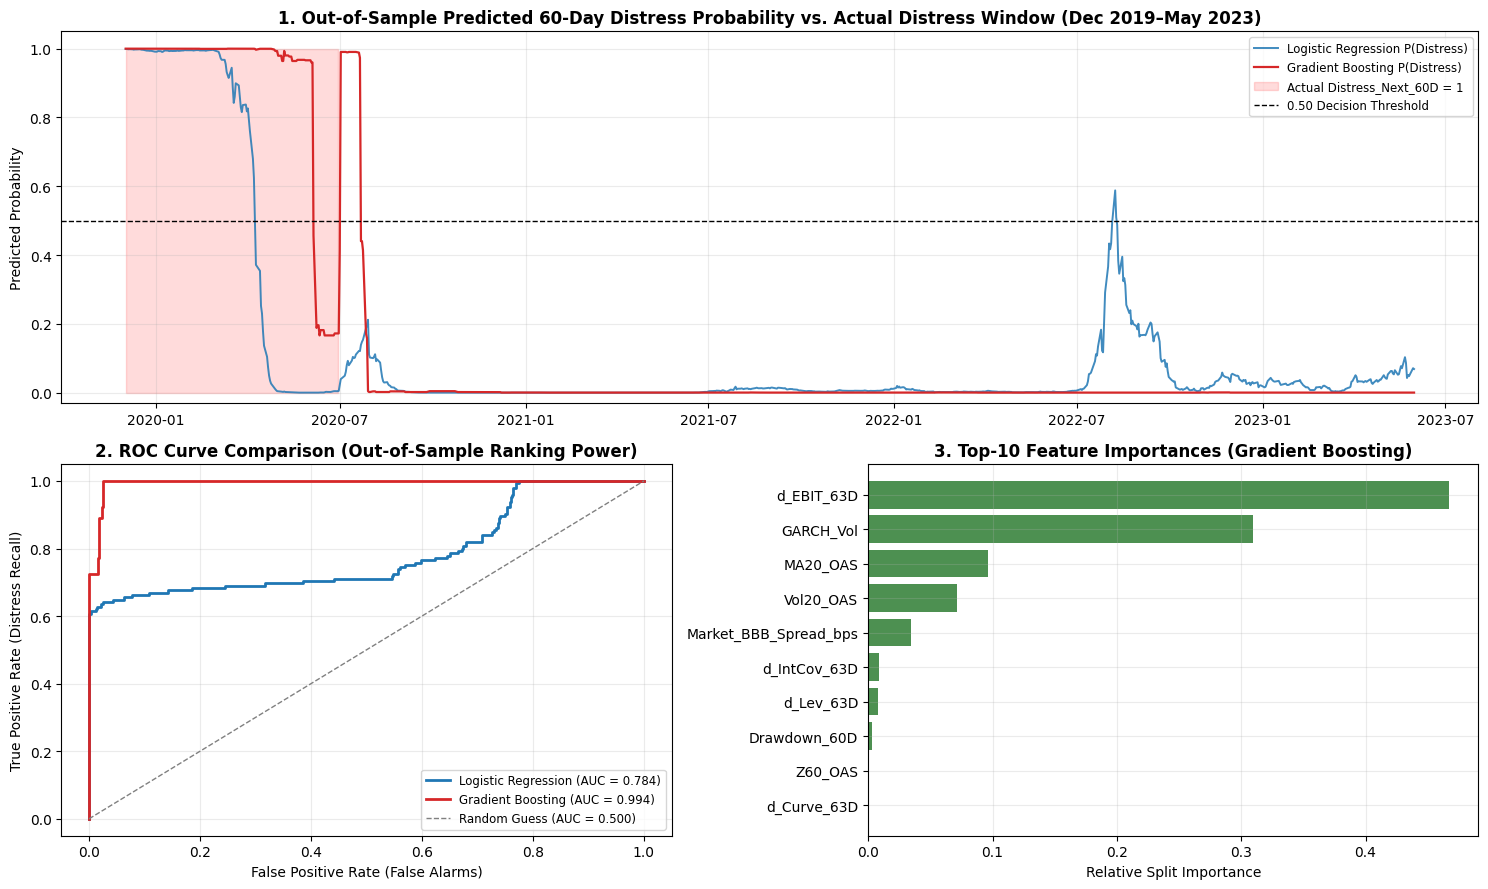

In [63]:
from sklearn.metrics import roc_curve, auc

fig = plt.figure(figsize=(15, 9))
ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)
ax2 = plt.subplot2grid((2, 2), (1, 0))
ax3 = plt.subplot2grid((2, 2), (1, 1))

# --- Panel 1: Predicted Default/Distress Probability Over Time vs. Actual Regime ---
ax1.plot(test.index, prob_lr, color="#1f77b4", lw=1.4, alpha=0.85, label="Logistic Regression P(Distress)")
ax1.plot(test.index, prob_gb, color="#d62728", lw=1.6, label="Gradient Boosting P(Distress)")
ax1.fill_between(test.index, 0, 1, where=(y_test == 1), color="red", alpha=0.14, label="Actual Distress_Next_60D = 1")
ax1.axhline(0.50, color="black", ls="--", lw=1.0, label="0.50 Decision Threshold")
ax1.set_ylim(-0.03, 1.05)
ax1.set_title("1. Out-of-Sample Predicted 60-Day Distress Probability vs. Actual Distress Window (Dec 2019–May 2023)", fontweight="bold")
ax1.set_ylabel("Predicted Probability")
ax1.legend(loc="upper right", fontsize=8.5)
ax1.grid(alpha=0.25)

# --- Panel 2: ROC Curves (Logistic vs. Gradient Boosting) ---
for name, probs, col in [("Logistic Regression", prob_lr, "#1f77b4"), ("Gradient Boosting", prob_gb, "#d62728")]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax2.plot(fpr, tpr, color=col, lw=2.0, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
ax2.plot([0, 1], [0, 1], color="gray", ls="--", lw=1.0, label="Random Guess (AUC = 0.500)")
ax2.set_title("2. ROC Curve Comparison (Out-of-Sample Ranking Power)", fontweight="bold")
ax2.set_xlabel("False Positive Rate (False Alarms)")
ax2.set_ylabel("True Positive Rate (Distress Recall)")
ax2.legend(loc="lower right", fontsize=8.5)
ax2.grid(alpha=0.25)

# --- Panel 3: Top-10 Feature Importances (Gradient Boosting) ---
imp = pd.Series(gb_model.feature_importances_, index=FEATURES).sort_values(ascending=True)
ax3.barh(imp.index, imp.values, color="#2e7d32", alpha=0.85)
ax3.set_title("3. Top-10 Feature Importances (Gradient Boosting)", fontweight="bold")
ax3.set_xlabel("Relative Split Importance")
ax3.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()